# Random Forest Classifier
**Dataset:** UCI Optdigits

This notebook compares tuned Random Forest models with all pixels and train-fold variance selection using five-fold stratified CV, then evaluates the selected configuration on the untouched official test split.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

cols = [f"pixel_{i}" for i in range(64)] + ["target"]

# Load train and test separately - IMPORTANT: never fit any transformer on test data
# Find data/raw from the current working directory or one of its parents.
workspace_root = next(
    parent for parent in [Path.cwd(), *Path.cwd().parents]
    if (parent / "data" / "raw").is_dir()
)
data_dir = workspace_root / "data" / "raw"

train = pd.read_csv("../../data/processed/optdigits_train_processed.csv", header=None, names=cols)
test  = pd.read_csv("../../data/processed/optdigits_test_processed.csv", header=None, names=cols)

print("Train shape:", train.shape)
print("Test shape:", test.shape)
train.head()

Train shape: (3823, 65)
Test shape: (1797, 65)


,pixel_0,pixel_1,pixel_2,pixel_3,pixel_4,pixel_5,pixel_6,pixel_7,pixel_8,pixel_9,...,pixel_55,pixel_56,pixel_57,pixel_58,pixel_59,pixel_60,pixel_61,pixel_62,pixel_63,target
0,0,1,6,15,12,1,0,0,0,7,...,0,0,0,6,14,7,1,0,0,0
1,0,0,10,16,6,0,0,0,0,7,...,0,0,0,10,16,15,3,0,0,0
2,0,0,8,15,16,13,0,0,0,1,...,0,0,0,9,14,0,0,0,0,7
3,0,0,0,3,11,16,0,0,0,0,...,0,0,0,0,1,15,2,0,0,4
4,0,0,5,14,4,0,0,0,0,0,...,0,0,0,4,12,14,7,0,0,6


In [2]:
from sklearn.feature_selection import VarianceThreshold

X = train.iloc[:, :64]

# --- Step A: variance threshold (fit on TRAIN ONLY) ---
selector = VarianceThreshold(threshold=0.05)
X_var = selector.fit_transform(X)
kept_mask = selector.get_support()
print("Features before:", X.shape[1], "-> after variance threshold:", X_var.shape[1])  # run this code to obtain actual value
print("Dropped columns:", list(X.columns[~kept_mask]))  # run this code to obtain actual value


Features before: 64 -> after variance threshold: 55
Dropped columns: ['pixel_0', 'pixel_8', 'pixel_16', 'pixel_24', 'pixel_31', 'pixel_32', 'pixel_39', 'pixel_47', 'pixel_56']


In [3]:
# --- Step B: correlation-based redundancy removal ---
corr_matrix = pd.DataFrame(X_var, columns=X.columns[kept_mask]).corr().abs()
upper_tri = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
to_drop = [col for col in upper_tri.columns if any(upper_tri[col] > 0.9)]
print("Highly correlated columns to drop:", to_drop)  # run this code to obtain actual value

final_features = [c for c in corr_matrix.columns if c not in to_drop]
print("Final feature count:", len(final_features))  # run this code to obtain actual value


Highly correlated columns to drop: ['pixel_58']
Final feature count: 54


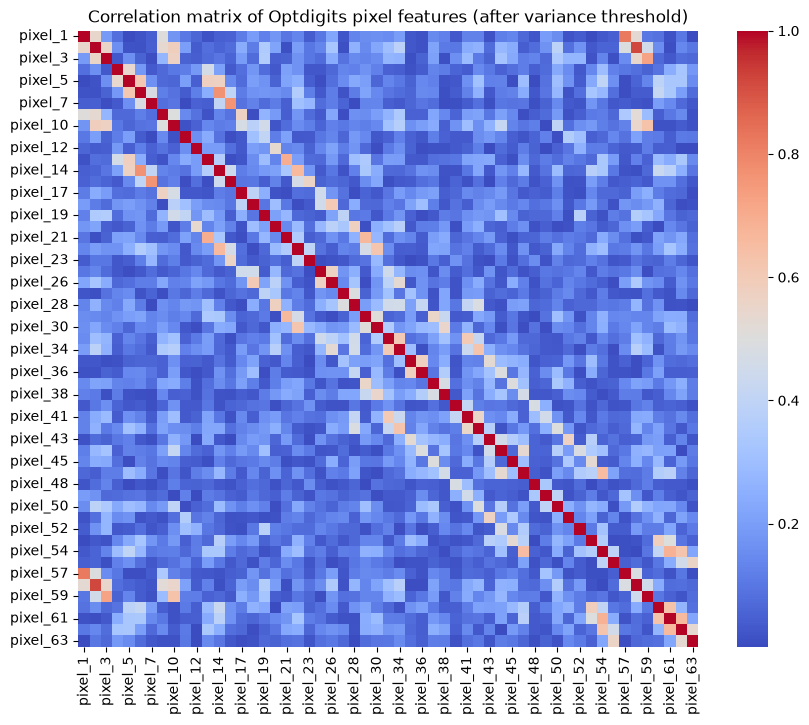

In [ ]:
# --- EDA visualization: correlation heatmap ---
output_dir = workspace_root / "results" / "eda_visualizations"
output_dir.mkdir(parents=True, exist_ok=True)

plt.figure(figsize=(10,8))
sns.heatmap(corr_matrix, cmap="coolwarm")
plt.title("Correlation matrix of Optdigits pixel features (after variance threshold)")
plt.savefig(output_dir / "member4_correlation_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()

## Model Evaluation

A Random Forest provides a nonlinear multiclass baseline and is relatively robust to pixel scaling. This experiment compares all 64 pixels with train-fold variance selection, using `VarianceThreshold` inside a Pipeline to avoid fitting selection on CV validation folds. `GridSearchCV` tunes the forest across 5-fold stratified CV. Accuracy and macro F1 are reported for CV and the untouched official test split. The notebook's correlation filter remains part of the feature-selection analysis; this model comparison isolates the effect of variance filtering.

,Model variant,CV accuracy,CV macro F1,Test accuracy,Test precision (macro),Test recall (macro),Test macro F1,Best parameters
0,Random Forest - variance selected,0.981689,0.981762,0.972176,0.972620,0.972150,0.972205,"{'classifier__max_features': 'sqrt', 'classifi..."
1,Random Forest - all pixels,0.981427,0.981516,0.972176,0.972438,0.972135,0.972161,"{'classifier__max_features': 'sqrt', 'classifi..."


CV-selected model: Random Forest - variance selected
Classification report on the held-out official test split:
              precision    recall  f1-score   support

           0     0.9888    0.9944    0.9916       178
           1     0.9628    0.9945    0.9784       182
           2     1.0000    0.9887    0.9943       177
           3     0.9719    0.9454    0.9584       183
           4     0.9891    1.0000    0.9945       181
           5     0.9833    0.9725    0.9779       182
           6     0.9888    0.9779    0.9833       181
           7     0.9882    0.9385    0.9628       179
           8     0.9432    0.9540    0.9486       174
           9     0.9101    0.9556    0.9322       180

    accuracy                         0.9722      1797
   macro avg     0.9726    0.9721    0.9722      1797
weighted avg     0.9727    0.9722    0.9722      1797



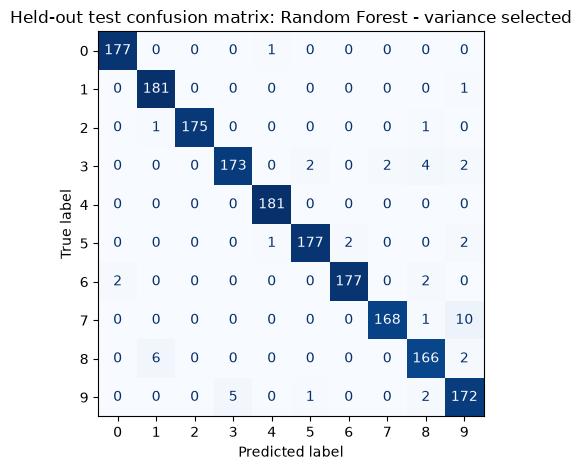

In [4]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import VarianceThreshold
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    f1_score,
    precision_score,
    recall_score,
)
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline

feature_cols = [f"pixel_{index}" for index in range(64)]
X_train = train[feature_cols]
y_train = train["target"].astype(int)
X_test = test[feature_cols]
y_test = test["target"].astype(int)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
experiments = {
    "Random Forest - all pixels": (
        Pipeline([("classifier", RandomForestClassifier(random_state=42, n_jobs=1))]),
        {
            "classifier__n_estimators": [100, 200],
            "classifier__max_features": ["sqrt"],
        },
    ),
    "Random Forest - variance selected": (
        Pipeline([
            ("selector", VarianceThreshold(threshold=0.05)),
            ("classifier", RandomForestClassifier(random_state=42, n_jobs=1)),
        ]),
        {
            "classifier__n_estimators": [100, 200],
            "classifier__max_features": ["sqrt"],
        },
    ),
}
results = []
best_models = {}
for variant_name, (pipeline, parameter_grid) in experiments.items():
    search = GridSearchCV(
        pipeline,
        parameter_grid,
        scoring={"accuracy": "accuracy", "macro_f1": "f1_macro"},
        refit="macro_f1",
        cv=cv,
        n_jobs=-1,
    )
    search.fit(X_train, y_train)
    best_models[variant_name] = search.best_estimator_
    predictions = search.predict(X_test)
    results.append({
        "Model variant": variant_name,
        "CV accuracy": search.cv_results_["mean_test_accuracy"][search.best_index_],
        "CV macro F1": search.best_score_,
        "Test accuracy": accuracy_score(y_test, predictions),
        "Test precision (macro)": precision_score(y_test, predictions, average="macro"),
        "Test recall (macro)": recall_score(y_test, predictions, average="macro"),
        "Test macro F1": f1_score(y_test, predictions, average="macro"),
        "Best parameters": search.best_params_,
    })

feature_model_comparison = pd.DataFrame(results).sort_values(
    "CV macro F1", ascending=False
).reset_index(drop=True)
display(feature_model_comparison)

best_variant = feature_model_comparison.loc[0, "Model variant"]
best_predictions = best_models[best_variant].predict(X_test)
print(f"CV-selected model: {best_variant}")
print("Classification report on the held-out official test split:")
print(classification_report(y_test, best_predictions, digits=4))
ConfusionMatrixDisplay.from_predictions(y_test, best_predictions, cmap="Blues", colorbar=False)
plt.title(f"Held-out test confusion matrix: {best_variant}")
plt.tight_layout()
plt.show()

### Results and conclusion

Variance selection reduced the feature set from 64 to 55 pixels. The selected-feature Random Forest reached 98.18% CV macro F1 and 97.22% test macro F1; the all-pixel model scored 98.15% and 97.22%, respectively. The nearly unchanged test result suggests removing low-variance pixels reduced input size without a material loss in this model, but the performance gain is negligible. The existing correlation analysis is not included in this model comparison, which isolates variance filtering. Limitations include the selected threshold and compact tree grid; future work could evaluate the correlation-filtered subset and compare computation time as well as score.